## Data Analysis and Visulization
**Ashley Dai**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import scipy.stats as stats
import numpy as np
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import f_oneway

In [2]:
# import preprocessed data
script_dir = os.path.dirname(os.path.abspath("data_analysis.ipynb")) # gets the path where this folder lives
file_path = os.path.join(script_dir, "..", "data", "games.csv")
chess_df = pd.read_csv(file_path)

### **Most/Least Popular Opening Moves (Top 10)**
**Visulization:** Frequency Bar Chart

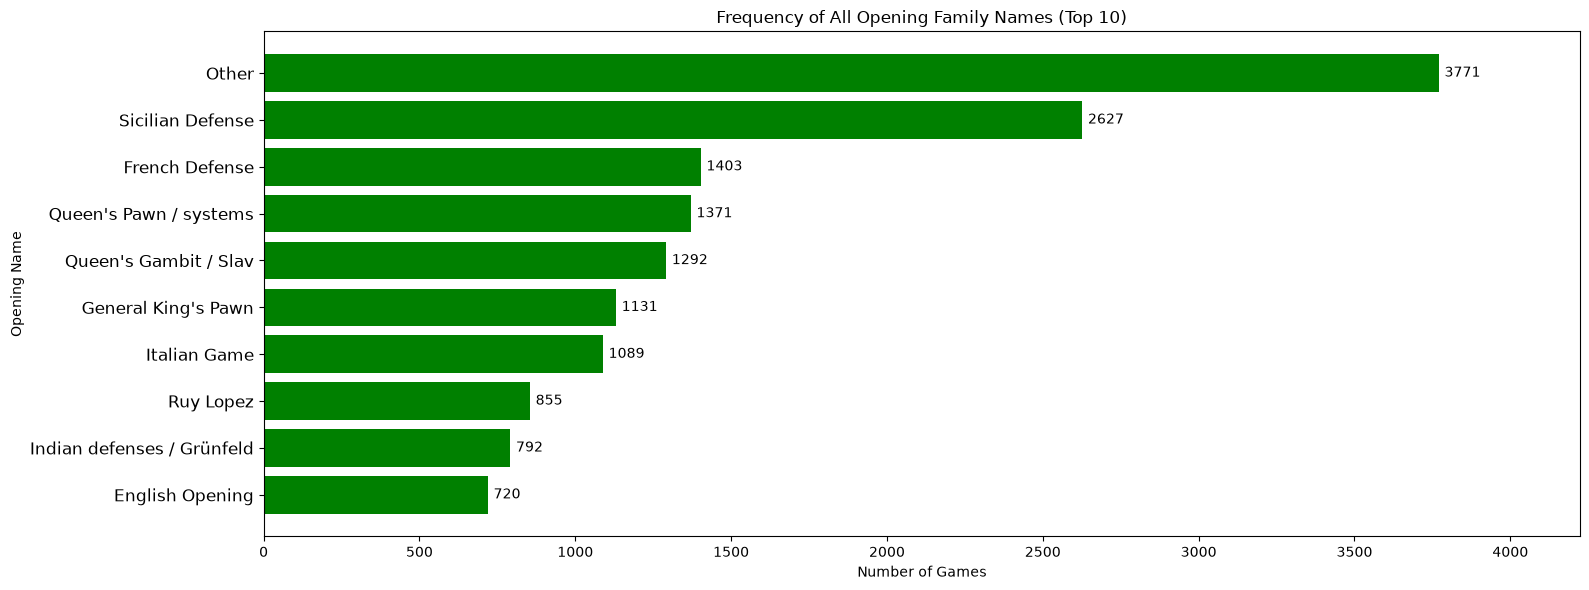

In [3]:
# NOTE: There is many different variations of each opening, so we decided to go with opening family
counts = chess_df["opening_family"].value_counts(dropna=False).head(10).sort_values(ascending=True)

# Scale the figure
fig_height = max(6, len(counts) * 0.35)
fig, ax = plt.subplots(figsize=(16, fig_height))

bars = ax.barh(counts.index.astype(str), counts.values, color="green")

# Label graph
ax.set_xlabel("Number of Games")
ax.set_ylabel("Opening Name")
ax.set_title(f"Frequency of All Opening Family Names (Top 10)")
ax.bar_label(bars, padding=4, fontsize=10)

ax.set_xlim(0, counts.max() * 1.12)
ax.tick_params(axis="y", labelsize=12)

plt.tight_layout()
plt.show()


**Analysis:** Looking at this frequency bar plot, it shows that "Other" has the highest frequency which means there is a lot of variation when it comes to opening moves. This overall means that users from Lichess.org are often using a variety of different opening moves. In addition, it seems that Sicilian Defense is often the most used in games on Lichess.org.

### **Is there statistically significant evidence that the proportion of White wins is higher than the proportion of Black wins (excluding draws)?**
**Visualization:** Pie Chart showing white/black overall winrate

**Statistical Test:** One Sample Proportion Z-Test

**p =** The proportion of games won by White

**Alpha (Significance Level)** = 0.05

**Null Hypothesis:** p = 0.5 
* The proportion of White wins DIFFERS from the proportion of Black wins on Lichess.org (White and Black HAVE A equal chance of winning).

**Alternative Hypothesis:** p > 0.5 
* The proportion of White wins is Higher than the proportion of Black wins on Lichess.org (White has a higher chance of winning than black).


**Assumptions:** randomly sampled, each game is independent, normal approximation (dataset contains over 20k records)

In [4]:
# Exclude draws
games_no_draws = chess_df[chess_df['winner'] != 'draw']

# Count wins
white_wins = (games_no_draws['winner'] == 'white').sum()
black_wins = (games_no_draws['winner'] == 'black').sum()

# Total games
n = len(games_no_draws)

# Calculate proportions
white_prop = white_wins / n
black_prop = black_wins / n

# One-sample proportion Z-test
z_stat, p_value = proportions_ztest(
    count=white_wins,
    nobs=n,
    value=0.5,
    alternative='larger'
)

print(f"White win proportion: {white_prop:.4f} ({white_prop*100:.2f}%)")
print(f"Black win proportion: {black_prop:.4f} ({black_prop*100:.2f}%)")
print(f"P-value: {p_value:.12f}")

White win proportion: 0.5234 (52.34%)
Black win proportion: 0.4766 (47.66%)
P-value: 0.000000000048


**Conclusion:** Because our p-value = 4.8E-11 < alpha = 0.05, we reject the Ho (null hypothesis). This means that there is statistically significant evidence that the proportion of White wins is higher than the proportion of Black wins. This means that players who play White have a advantage in winning the match on Lichess.org.

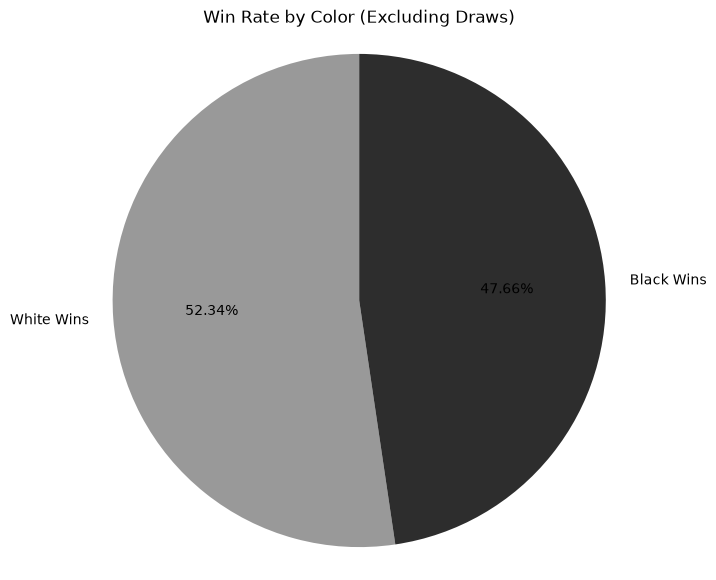

In [5]:
# Visualization
# Win counts
labels = ['White Wins', 'Black Wins']
sizes = [white_wins, black_wins]

plt.figure(figsize=(7, 7))
plt.pie(
    sizes,
    labels=labels,
    autopct='%1.2f%%',
    colors=['#999999', '#2d2d2d'],
    startangle=90
)

plt.title('Win Rate by Color (Excluding Draws)')
plt.axis('equal')
plt.show()

### **Which opening moves have highest/lowest win rates for white and black?**
**Visulization:** Bar Chart

In [6]:
# Create boolean columns for White and Black wins
chess_df["white_win"] = chess_df["winner"] == "white"
chess_df["black_win"] = chess_df["winner"] == "black"

# Calculate win rate (proportion) for each color
opening_stats = (
    chess_df.groupby("opening_family", as_index=False)
    .agg(
        total_games=("id", "count"),
        white_win_rate=("white_win", "mean"),
        black_win_rate=('black_win', "mean"),
    )
)

# Convert proportions to percentages
opening_stats["white_win_rate"] = (opening_stats["white_win_rate"] * 100).round(2)
opening_stats["black_win_rate"] = (opening_stats["black_win_rate"] * 100).round(2)

# Filter out rare opening families 
min_games = 100
reliable_openings = opening_stats[opening_stats["total_games"] >= min_games]

# Sort win rates (descending order)
top_white = reliable_openings.sort_values(by="white_win_rate", ascending=False).head(5)
bottom_white = reliable_openings.sort_values(by="white_win_rate", ascending=True).head(5)

top_black = reliable_openings.sort_values(by="black_win_rate", ascending=False).head(5)
bottom_black = reliable_openings.sort_values(by="black_win_rate", ascending=True).head(5)



In [7]:
print("--------------Highest Win Rate for White---------------")
print(top_white[["opening_family", "total_games", "white_win_rate"]]
      .to_string(index=False, formatters={'white_win_rate': '{:.2f}%'.format}))

print("\n---------------Lowest Win Rate for White---------------")
print(bottom_white[["opening_family", "total_games", "white_win_rate"]]
      .to_string(index=False, formatters={'white_win_rate': '{:.2f}%'.format}))

print("\n--------------Highest Win Rate for Black---------------")
print(top_black[["opening_family", "total_games", "black_win_rate"]]
      .to_string(index=False, formatters={'black_win_rate': '{:.2f}%'.format}))

print("\n---------------Lowest Win Rate for Black---------------")
print(bottom_black[["opening_family", "total_games", "black_win_rate"]]
      .to_string(index=False, formatters={'black_win_rate': '{:.2f}%'.format}))


--------------Highest Win Rate for White---------------
       opening_family  total_games white_win_rate
        King's Gambit          237         58.23%
     Philidor Defense          690         57.39%
      English Opening          720         54.86%
               Scotch          467         54.18%
Petrov / Russian Game          346         53.18%

---------------Lowest Win Rate for White---------------
            opening_family  total_games white_win_rate
      Van't Kruijs Opening          368         34.24%
Indian defenses / Grünfeld          792         44.57%
          Sicilian Defense         2627         45.76%
    Queen's Pawn / systems         1371         46.90%
              Italian Game         1089         48.58%

--------------Highest Win Rate for Black---------------
            opening_family  total_games black_win_rate
      Van't Kruijs Opening          368         61.41%
          Sicilian Defense         2627         49.41%
Indian defenses / Grünfeld         

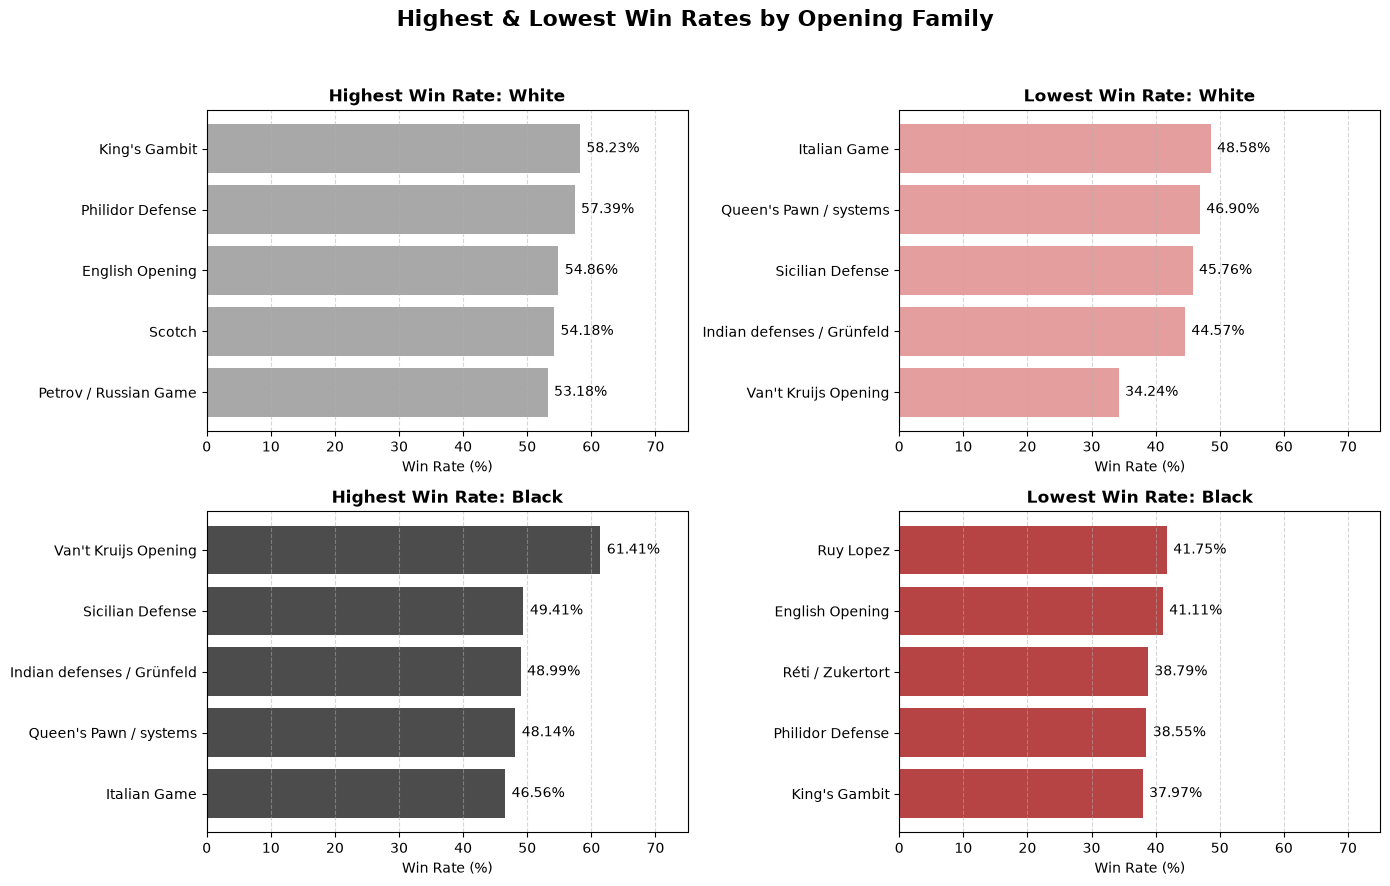

In [8]:
# 2x2 subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('Highest & Lowest Win Rates by Opening Family', fontsize=16, fontweight='bold')

# format/color each bar graph
charts = [
    (axes[0, 0], top_white, 'white_win_rate', 'Highest Win Rate: White', "#999999"),
    (axes[0, 1], bottom_white, 'white_win_rate', 'Lowest Win Rate: White', "#e08d8d"),
    (axes[1, 0], top_black, 'black_win_rate', 'Highest Win Rate: Black', "#2d2d2d"),
    (axes[1, 1], bottom_black, 'black_win_rate', 'Lowest Win Rate: Black', "#aa2323"),
]

for ax, data, col, title, color in charts:
    # Sort ascending order
    plot_data = data.sort_values(by=col, ascending=True)
    bars = ax.barh(plot_data['opening_family'], plot_data[col], color=color, alpha=0.85)
    
    # Label graph
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Win Rate (%)')
    ax.set_xlim(0, 75)  
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    
    # Add exact percentage labels next to each bar
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + 1,
            bar.get_y() + bar.get_height() / 2,
            f'{width:.2f}%',
            va='center',
            fontsize=10
        )

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


### **Does the average game length differ between the top 10 most popular opening moves?**
**Visualization:** Box Plots

**Statistical Test:** One Way ANOVA Test

**μ =** The population mean game length for a opening move on Lichess.org.

**Alpha (Significance Level)** = 0.05

**Null Hypothesis:** H<sub>0</sub>: μ<sub>1</sub> = μ<sub>2</sub> = ... = μ<sub>10</sub> 
* All 10 most popular openings have the same population mean game length.

**Alternative Hypothesis:** At least one of the 10 most popular openings has a different population mean game length.

**Assumptions:** each game is independent, normality (look below at QQ-plots), constant variance (look at the residual plot).

In [9]:
# Remove values categorized as "other" in opening family
chess_clean = chess_df[chess_df['opening_family'].str.lower() != 'other']

# Top 10 most popular opening families
top_10 = chess_clean['opening_family'].value_counts().head(10).index

# Filter dataset
top_games = chess_clean[chess_clean['opening_family'].isin(top_10)]

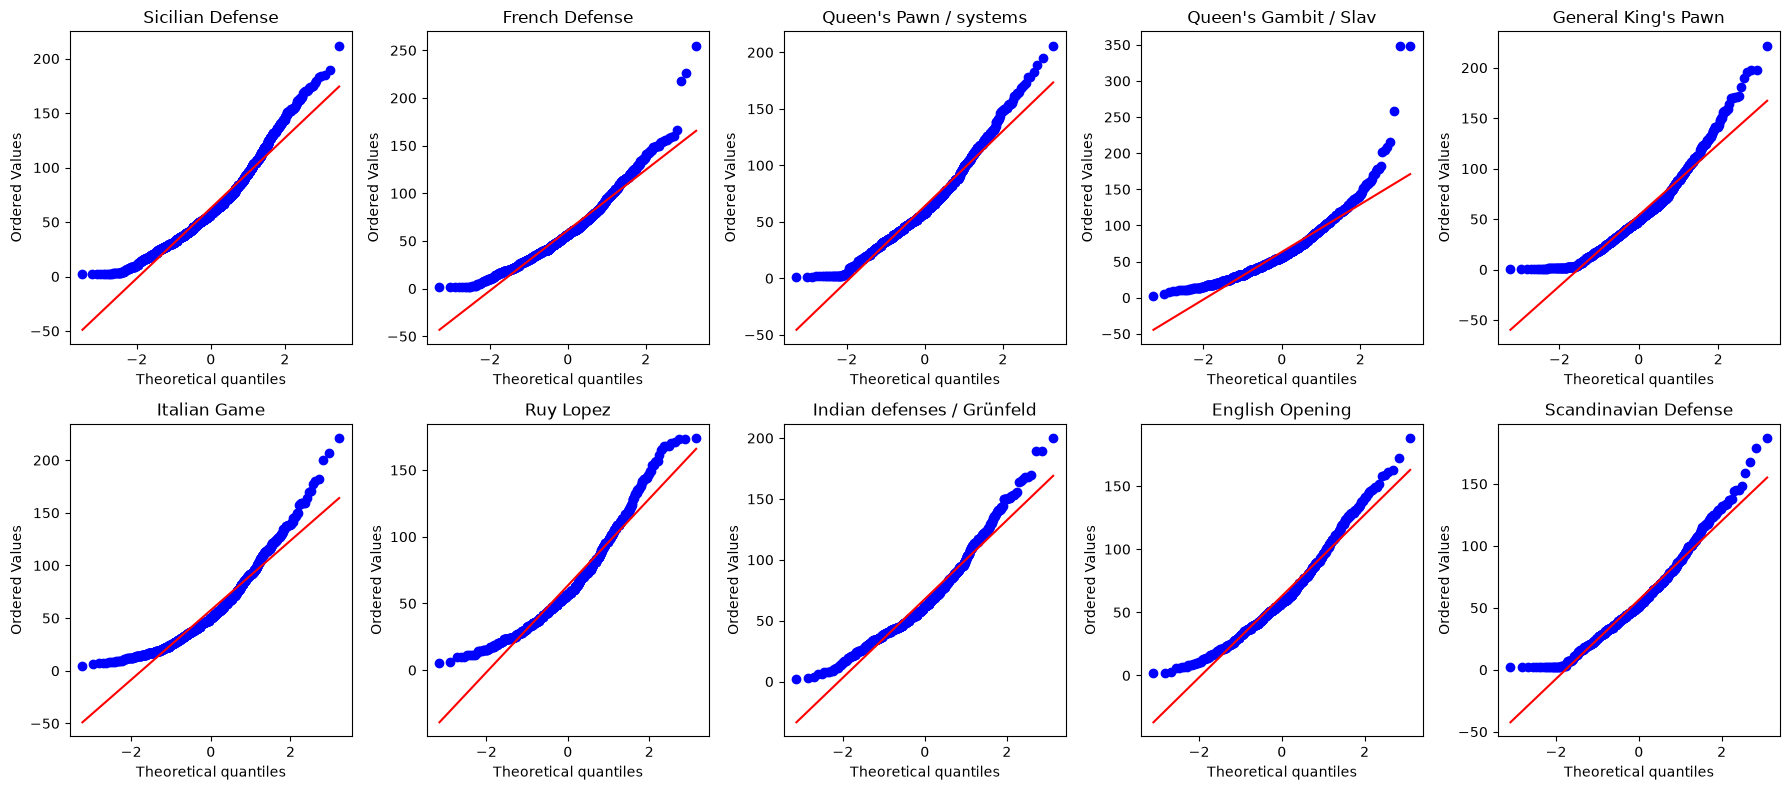

In [10]:
# Check for Normality, create QQ-Plot (Quanitle-Quantile Plot)
fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for opening, ax in zip(top_10, axes.flatten()):
    group = top_games[top_games['opening_family'] == opening]['turns']

    stats.probplot(group, dist="norm", plot=ax)
    ax.set_title(opening)

plt.tight_layout()
plt.show()

**Analysis:** After looking at the QQ-plot, you can see the points curving away from the line at the end which suggests that the data is right skewed. Thus we can not assume normality and need to preform a transformation. Below we preform a square root transformation to help reduce the right skewedness.

In [11]:
# Square Root Transformation
top_games['sqrt_turns'] = np.sqrt(top_games['turns'])

# Create groups
groups_sqrt = [
    top_games[top_games['opening_family'] == opening]['sqrt_turns']
    for opening in top_10
]

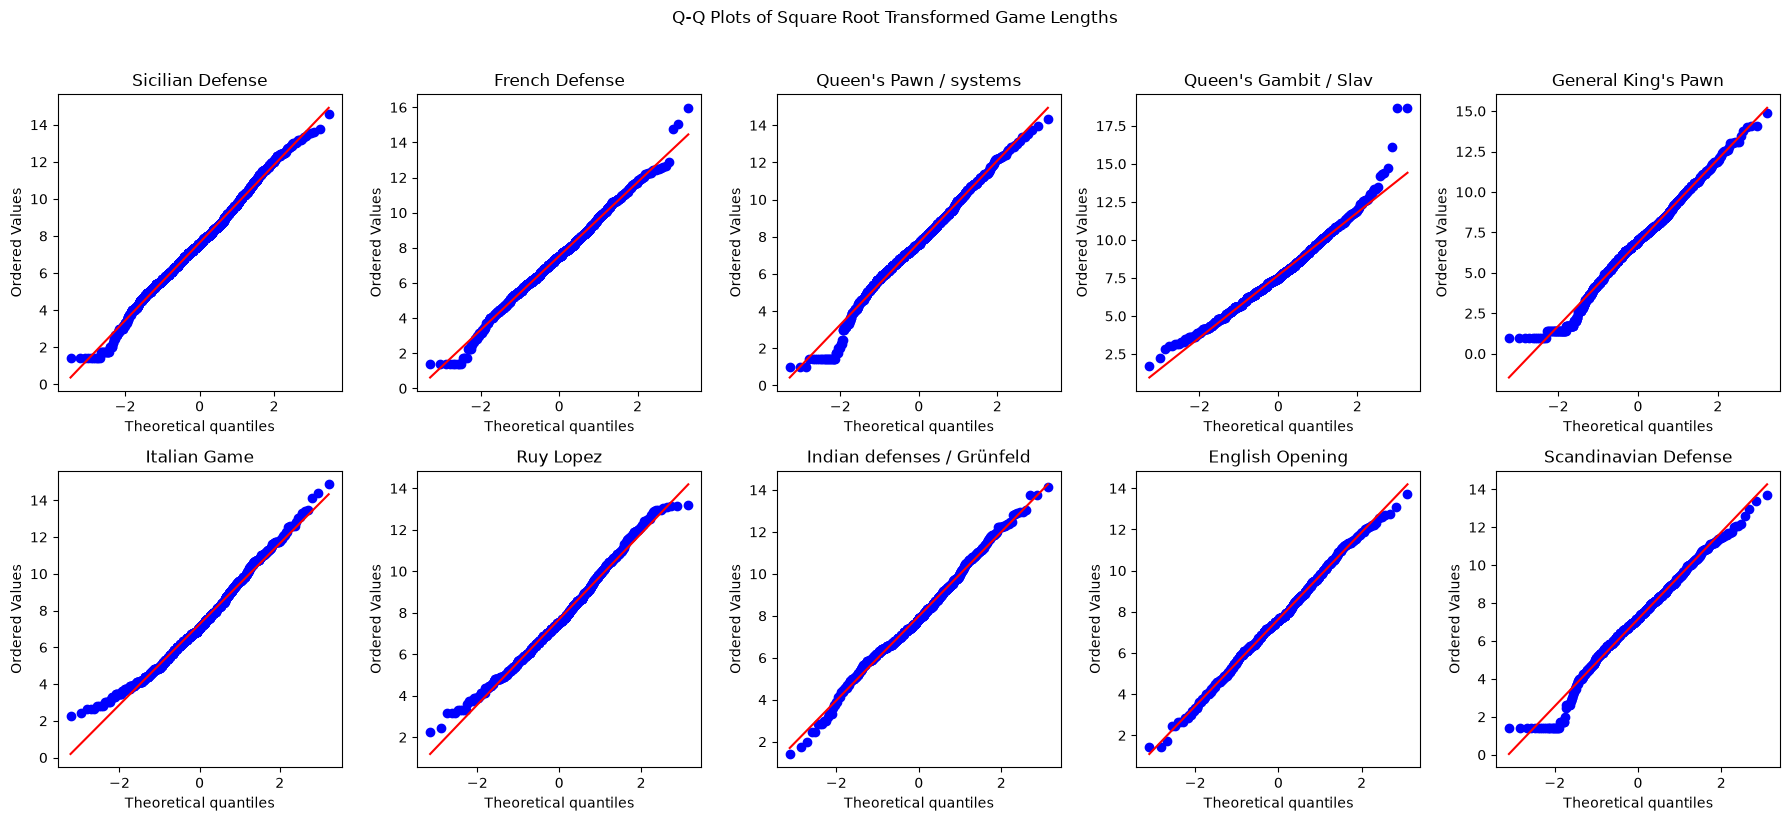

In [12]:
# New QQ-Plot after Root Transformation
fig, axes = plt.subplots(2, 5, figsize=(18, 8))

for opening, ax in zip(top_10, axes.flatten()):
    group = top_games[top_games['opening_family'] == opening]['sqrt_turns']

    stats.probplot(group, dist="norm", plot=ax)
    ax.set_title(opening)

plt.suptitle('Q-Q Plots of Square Root Transformed Game Lengths', y=1.02)
plt.tight_layout()
plt.show()

**Analysis:** This new QQ-plot after the root transformation shows that the points closely follow the line. This means that we can now assume normality for of test.

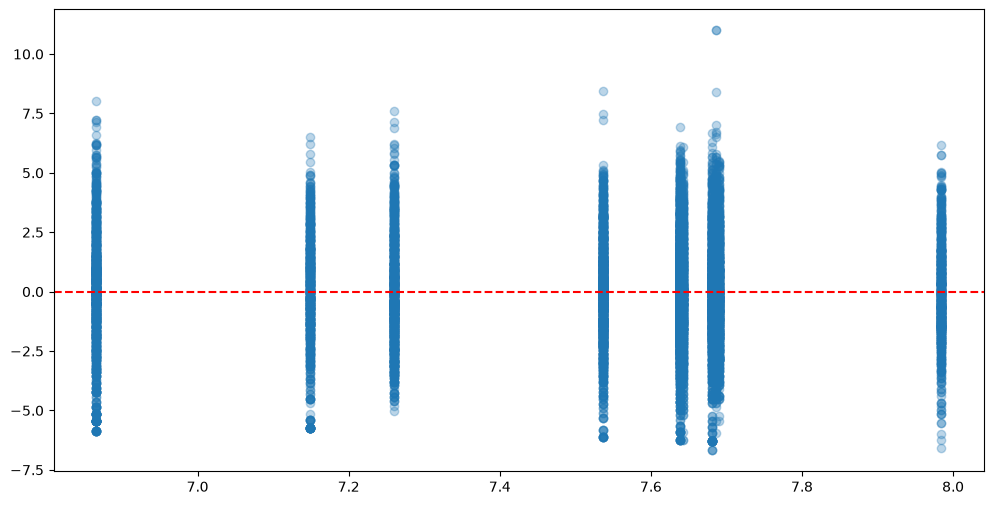

In [13]:
# Check for constant variance, create Residual Plot
top_games['group_mean'] = (
    top_games.groupby('opening_family')['sqrt_turns'].transform('mean')
)

# Calculate residuals
top_games['residual'] = top_games['sqrt_turns'] - top_games['group_mean']

# Create residual plot
plt.figure(figsize=(12, 6))

plt.scatter(
    top_games['group_mean'],
    top_games['residual'],
    alpha=0.3
)

plt.axhline(y=0, color='red', linestyle='--')

**Analysis:** Looking at the residual plot, there appears to be no distinct cone shape, so we can assume that the constant variance assumption is met.

In [14]:
# One-Way Anova Test
f_stat, p_value = f_oneway(*groups_sqrt)

print("P-value:", p_value)

P-value: 5.300674747167448e-39


**Conclusion:** Because our p-value = 5.3007E-39 < alpha = 0.05, we reject the Ho (null hypothesis). This means that there is statistically significant evidence that at least one of the 10 most popular openings has a different population mean game length. 

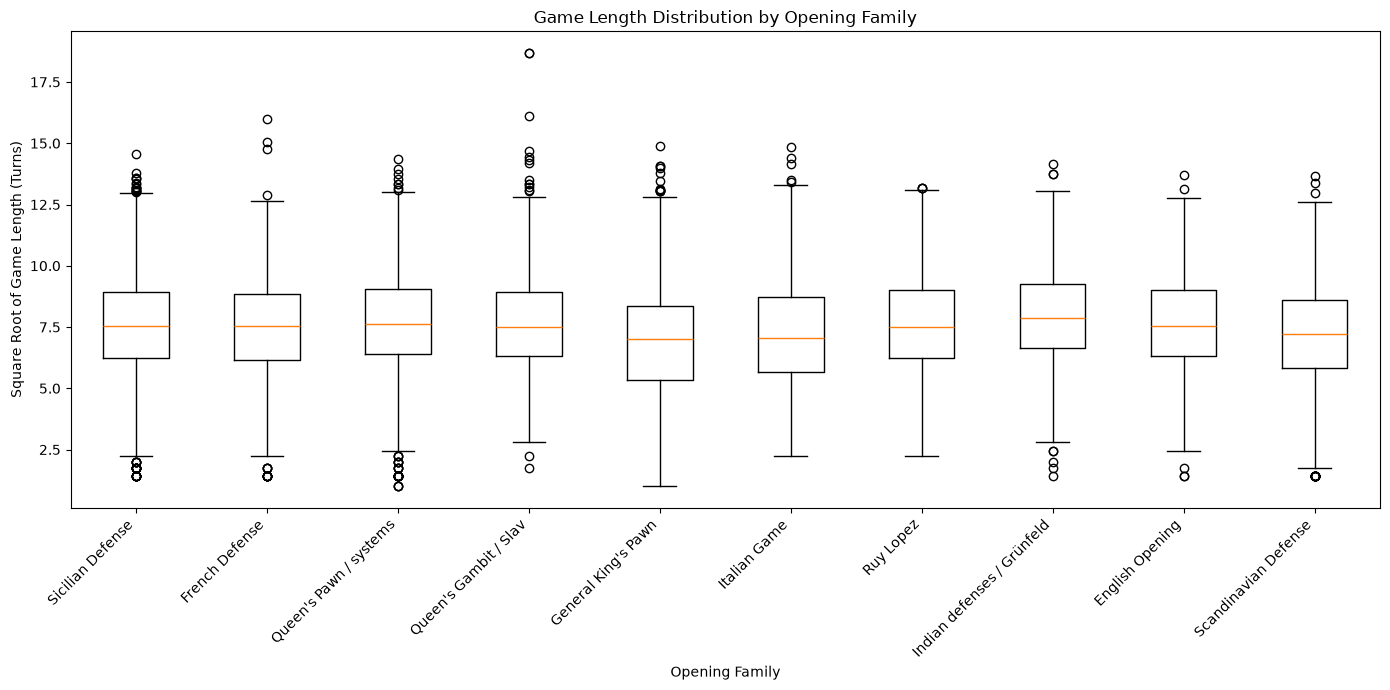

In [15]:
# Visualization
plt.figure(figsize=(14, 7))

plt.boxplot(groups_sqrt, tick_labels=top_10)

plt.title('Game Length Distribution by Opening Family')
plt.xlabel('Opening Family')
plt.ylabel('Square Root of Game Length (Turns)')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

**Analysis:** Looking at the distributions of each opening family, a few contain large outliers that could contribute to differences in the group means. Aside from these outliers, the medians and interquartile ranges are relatively similar across the 10 opening families. Although the One-Way ANOVA concluded that at least one population mean differs, this does not necessarily mean that the average game lengths between the opening families have large or practically meaningful differences.